# MLP com ModelNet10: otimização de hiperparâmetros

**Desenvolvedora:** Liane Heidemann

**Uso de IA:** foram usados Claude Opus 5.5 e GPT-6.1 Sol.

Notebook construído por etapas, seguindo `doc/passo-a-passo.md`.

## Etapa 0: Ambiente e configuração

### 0.1 Versões

Versões usadas neste notebook (Python 3.11.9, registrado também em `.python-version`).

In [1]:
import sys, numpy, pandas, sklearn, optuna, h5py

# Registra as versões para garantir reprodutibilidade
print('Python', sys.version.split()[0])
for m in (numpy, pandas, sklearn, optuna, h5py):
    print(m.__name__, m.__version__)

Python 3.13.3
numpy 2.2.4
pandas 2.2.3
sklearn 1.9.1
optuna 5.0.0
h5py 3.16.0


### 0.2 Constantes e caminhos

Seed fixa para reprodutibilidade e caminhos dos arquivos.

In [2]:
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from pathlib import Path

# Seed única, reutilizada em folds, buscas e modelos
SEED = 42

# Arquivos oficiais do ModelNet10, com caminho relativo à pasta notebooks/
DATA_DIR = Path('../dataset/modelnet10_hdf5')
TRAIN_FILE = DATA_DIR / 'modelnet10_train_0.h5'
TEST_FILE = DATA_DIR / 'modelnet10_test_0.h5'

# Pasta onde os gráficos são salvos
OUTPUT_DIR = Path('../output')
OUTPUT_DIR.mkdir(exist_ok=True)

# O arquivo traz só ids de 0 a 9; os nomes seguem a ordem alfabética padrão do ModelNet10
CLASS_NAMES = ['Banheira', 'Cama', 'Cadeira', 'Mesa de escritório', 'Cômoda',
               'Monitor', 'Mesa de cabeceira', 'Sofá', 'Mesa', 'Vaso sanitário']

## Etapa 2: Carregar e conferir os dados

Cada objeto é uma **nuvem de 2.048 pontos** (X, Y, Z) com um rótulo de 0 a 9. Aqui só *inspecionamos* os dados; o teste não é usado para nenhuma decisão.

### 2.1 Carregamento

In [3]:
def load_h5(path):
    """Lê um arquivo HDF5 e devolve (nuvens, rótulos)."""
    with h5py.File(path, 'r') as f:
        # data: (n_objetos, 2048, 3) | label: (n_objetos,)
        return f['data'][:], f['label'][:].ravel()


X_train_pts, y_train = load_h5(TRAIN_FILE)
X_test_pts, y_test = load_h5(TEST_FILE)

# Esperado: treino (3991, 2048, 3) e teste (908, 2048, 3)
print('treino:', X_train_pts.shape, y_train.shape, X_train_pts.dtype)
print('teste :', X_test_pts.shape, y_test.shape, X_test_pts.dtype)

treino: (3991, 2048, 3) (3991,) float32
teste : (908, 2048, 3) (908,) float32


### 2.2 Distribuição por classe

O arquivo traz só ids numéricos (0–9), sem nomes. Classes desbalanceadas justificam usar **validação estratificada** e **F1 macro**.

,treino,teste,treino_%,teste_%
0: Banheira,106,50,2.7,5.5
1: Cama,515,100,12.9,11.0
2: Cadeira,889,100,22.3,11.0
3: Mesa de escritório,200,86,5.0,9.5
4: Cômoda,200,86,5.0,9.5
5: Monitor,465,100,11.7,11.0
6: Mesa de cabeceira,200,86,5.0,9.5
7: Sofá,680,100,17.0,11.0
8: Mesa,392,100,9.8,11.0
9: Vaso sanitário,344,100,8.6,11.0


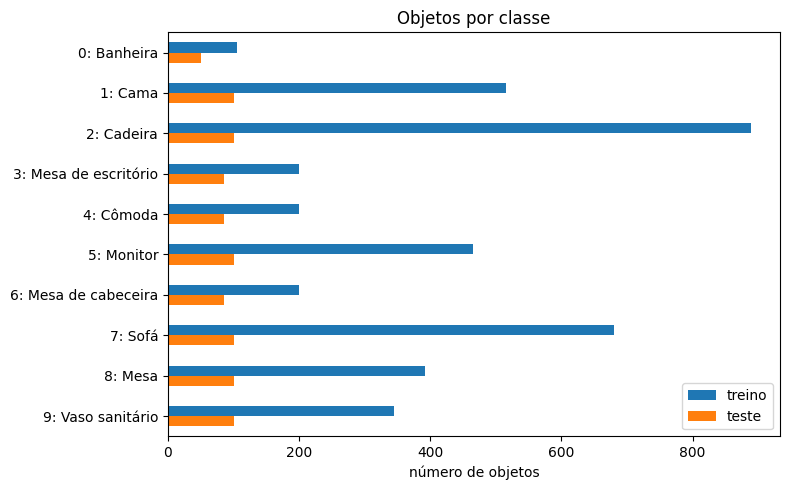

In [4]:
# Contagem de objetos por classe em treino e teste
dist = pd.DataFrame({
    'treino': pd.Series(y_train).value_counts().sort_index(),
    'teste': pd.Series(y_test).value_counts().sort_index(),
})
dist.index = [f'{i}: {n}' for i, n in enumerate(CLASS_NAMES)]

# Percentual de cada classe dentro do próprio conjunto
dist['treino_%'] = (100 * dist['treino'] / dist['treino'].sum()).round(1)
dist['teste_%'] = (100 * dist['teste'] / dist['teste'].sum()).round(1)
display(dist)

# Barras horizontais, pois os nomes das classes são longos para o eixo X
ax = dist[['treino', 'teste']].plot.barh(figsize=(8, 5), title='Objetos por classe')

# Classe 0 no topo e legenda na região vazia, sem cobrir as barras
ax.invert_yaxis()
ax.legend(loc='lower right')
ax.set_xlabel('número de objetos'); ax.set_ylabel('')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '01_objetos_por_classe.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.3 Valores ausentes, inválidos e faixa das coordenadas

In [5]:
for nome, pts, y in [('treino', X_train_pts, y_train), ('teste', X_test_pts, y_test)]:
    print(f'--- {nome} ---')

    # Valores ausentes ou inválidos nas coordenadas
    print('NaN:', int(np.isnan(pts).sum()), '| inf:', int(np.isinf(pts).sum()))
    print('rótulos únicos:', np.unique(y))

    # Faixa global de X, Y e Z (reshape junta os pontos de todos os objetos)
    print('min por eixo:', pts.reshape(-1, 3).min(0).round(3))
    print('max por eixo:', pts.reshape(-1, 3).max(0).round(3))

    # Tamanho do objeto: maior extensão entre os 3 eixos (varia entre objetos)
    extent = (pts.max(1) - pts.min(1)).max(1)
    print('maior extensão por objeto: min %.3f | mediana %.3f | max %.3f'
          % (extent.min(), np.median(extent), extent.max()))

    # Centróide médio perto de 0 indica objetos já centrados
    print('centróide médio:', pts.mean(1).mean(0).round(3))

--- treino ---
NaN: 0 | inf: 0
rótulos únicos: [0 1 2 3 4 5 6 7 8 9]


min por eixo: [-0.996 -0.992 -1.   ]


max por eixo: [0.991 0.994 1.   ]


maior extensão por objeto: min 0.936 | mediana 1.525 | max 1.997
centróide médio: [ 0. -0.  0.]
--- teste ---


NaN: 0 | inf: 0
rótulos únicos: [0 1 2 3 4 5 6 7 8 9]
min por eixo: [-0.973 -0.949 -0.997]


max por eixo: [0.987 0.996 0.99 ]


maior extensão por objeto: min 0.926 | mediana 1.489 | max 1.980
centróide médio: [-0. -0. -0.]


### 2.4 Um exemplo de cada classe

O primeiro objeto de treino de cada classe, colorido pela altura (eixo Z).

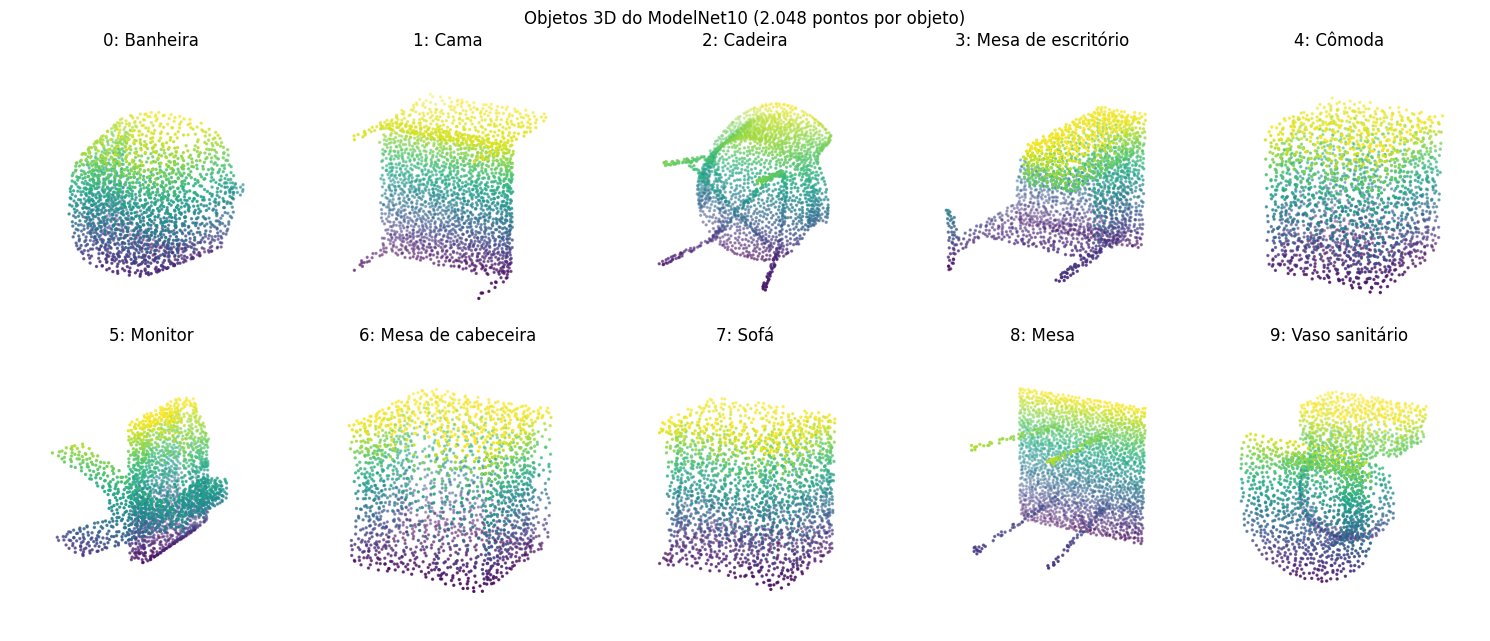

In [6]:
fig = plt.figure(figsize=(15, 6.5))
for c in range(10):
    # Primeiro objeto de treino da classe c, com shape (2048, 3)
    p = X_train_pts[np.where(y_train == c)[0][0]]

    ax = fig.add_subplot(2, 5, c + 1, projection='3d')

    # Cor pela altura (Z); a viridis não tem extremo claro e aparece bem no fundo branco
    ax.scatter(p[:, 0], p[:, 1], p[:, 2], c=p[:, 2], cmap='viridis', s=2)

    # Ângulo de visão e eixos com a mesma escala
    ax.view_init(elev=20, azim=-60)
    ax.set_box_aspect((1, 1, 1))
    ax.set_title(f'{c}: {CLASS_NAMES[c]}'); ax.set_axis_off()

fig.suptitle('Objetos 3D do ModelNet10 (2.048 pontos por objeto)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '02_exemplo_por_classe.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.5 Os mesmos objetos em três vistas

Cada imagem olha os objetos ao longo de um eixo diferente: frontal (Y), lateral (X) e topo (Z).

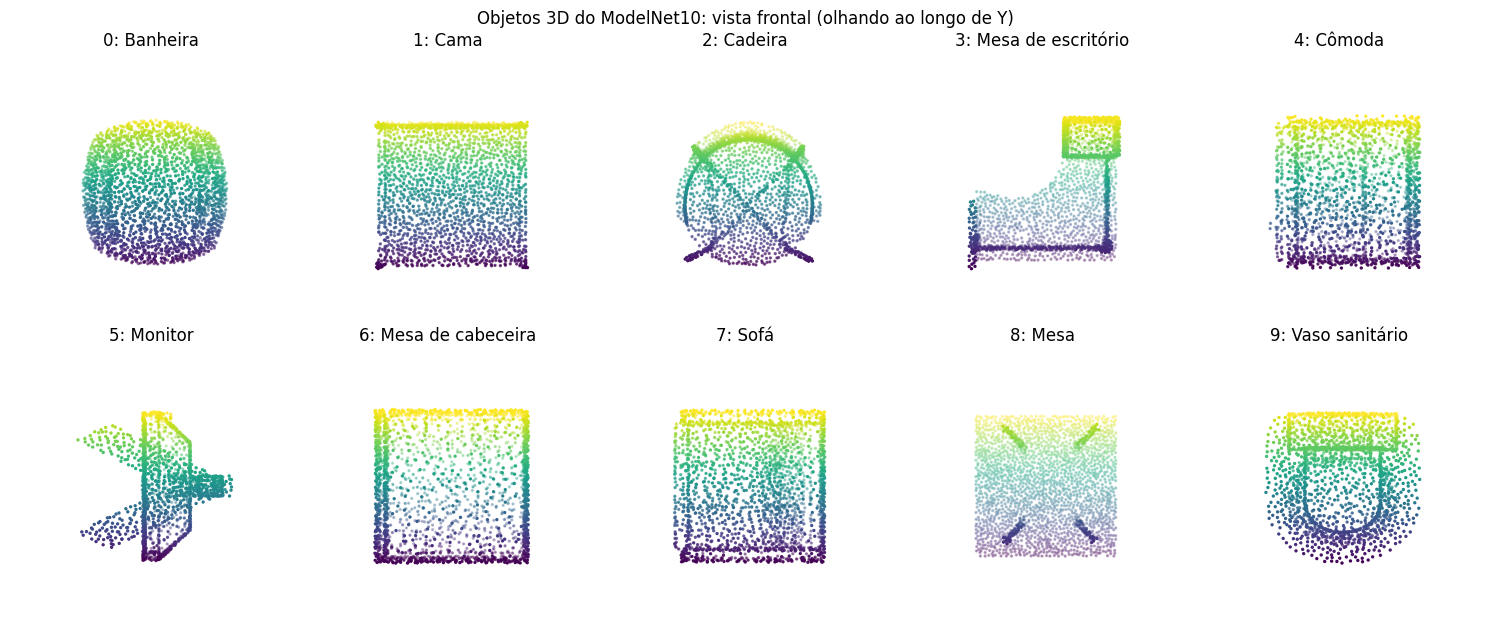

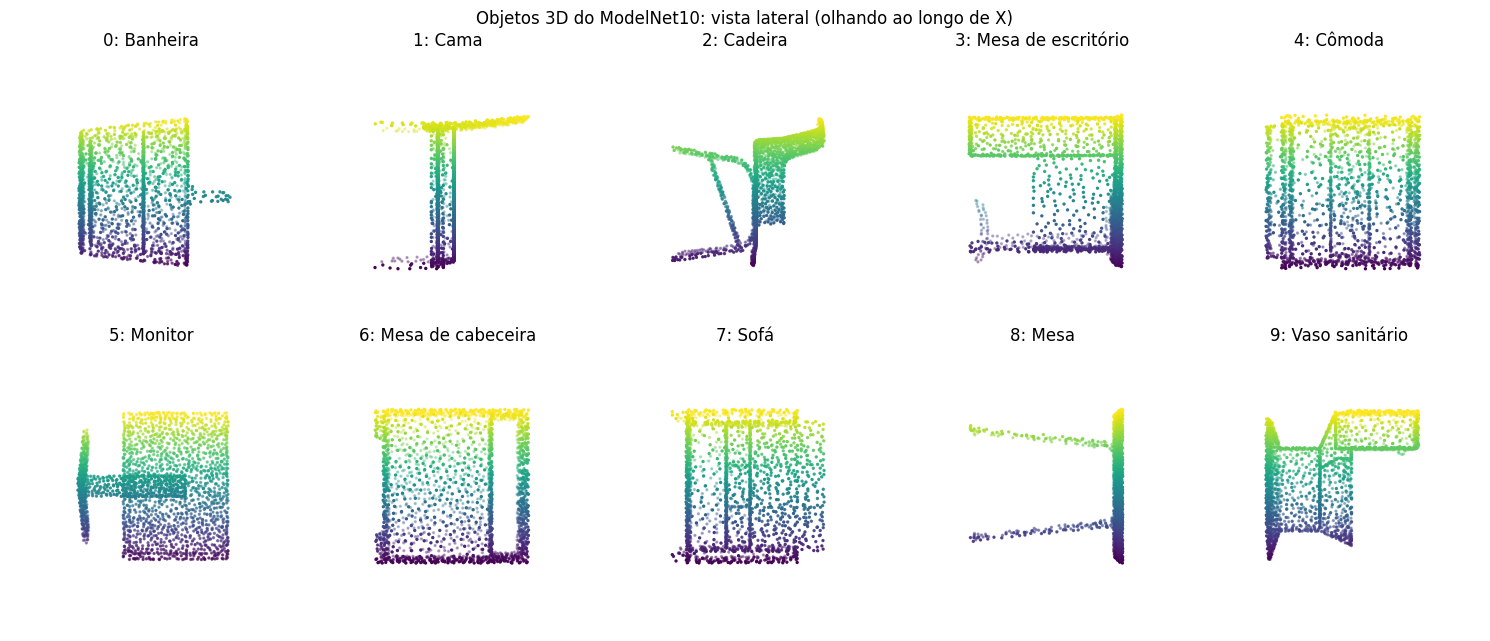

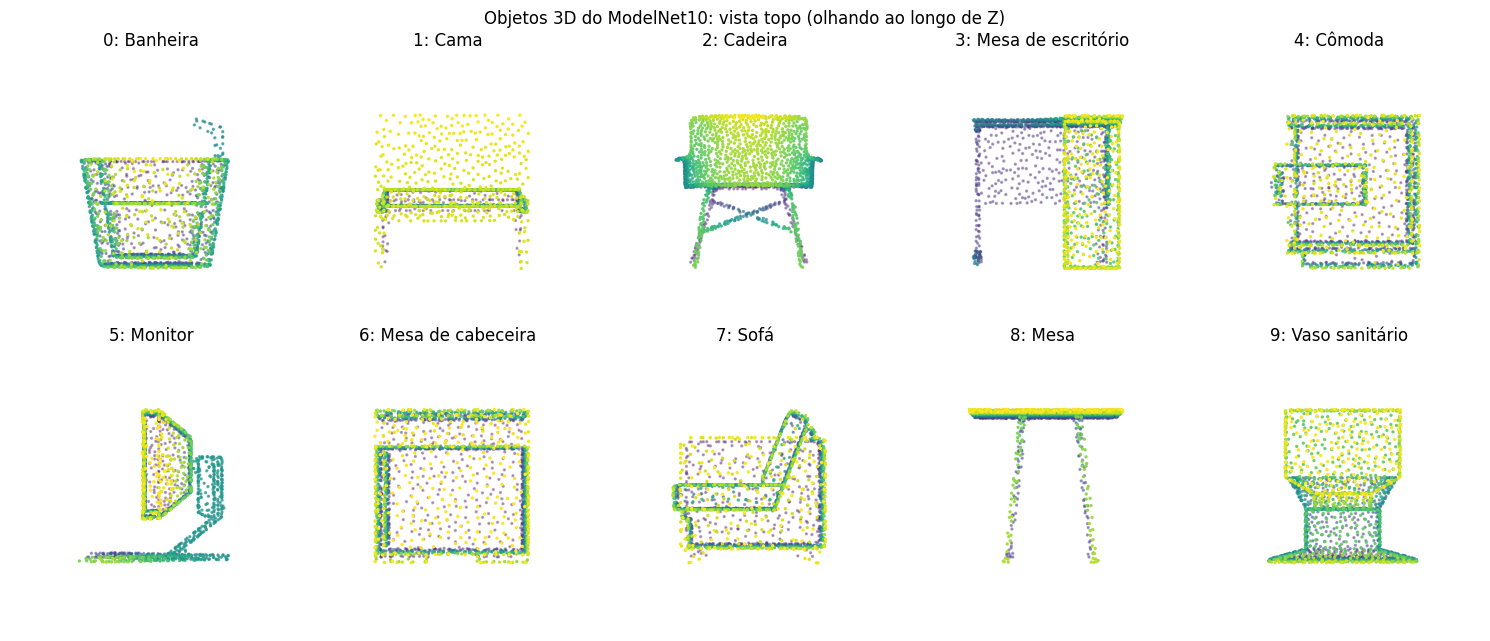

In [7]:
# Três pontos de vista: cada um olha o objeto ao longo de um eixo
VIEWS = {
    'frontal (olhando ao longo de Y)': dict(elev=0, azim=-90),
    'lateral (olhando ao longo de X)': dict(elev=0, azim=0),
    'topo (olhando ao longo de Z)': dict(elev=90, azim=-90),
}

for i, (nome, view) in enumerate(VIEWS.items(), start=1):
    fig = plt.figure(figsize=(15, 6.5))
    for c in range(10):
        # Primeiro objeto de treino da classe c, com shape (2048, 3)
        p = X_train_pts[np.where(y_train == c)[0][0]]

        ax = fig.add_subplot(2, 5, c + 1, projection='3d')
        ax.scatter(p[:, 0], p[:, 1], p[:, 2], c=p[:, 2], cmap='viridis', s=2)

        # Ângulo de visão deste gráfico e eixos com a mesma escala
        ax.view_init(**view)
        ax.set_box_aspect((1, 1, 1))
        ax.set_title(f'{c}: {CLASS_NAMES[c]}'); ax.set_axis_off()

    fig.suptitle(f'Objetos 3D do ModelNet10: vista {nome}')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'02_{i}_vista_{nome.split()[0]}.png', dpi=150, bbox_inches='tight')
    plt.show()

## Etapa 3: Preparar a entrada da MLP

Uma MLP precisa de um vetor de tamanho fixo e com ordem, e uma nuvem de pontos não tem ordem. Por isso dividimos o espaço em **8×8×8 = 512 células** (voxels): cada célula vale **1** se contém algum ponto e **0** caso contrário.

**Transformação (determinística, por objeto):**
1. Centralizar o objeto no centro da sua caixa delimitadora.
2. Dividir pela maior extensão entre os eixos, o que coloca o objeto em [0, 1]³ sem deformar a proporção.
3. Multiplicar por 8 e truncar para obter o índice (0 a 7) da célula de cada ponto.

Cada objeto usa só os próprios pontos, então nada é ajustado com o conjunto de teste e a mesma função vale para treino e teste.

### 3.1 Transformação

In [8]:
# Células por eixo, o que dá 8*8*8 = 512 atributos
GRID = 8


def voxelize(points, grid=GRID):
    """Converte uma nuvem (n_pontos, 3) em um vetor binário de grid**3 posições."""
    mins, maxs = points.min(0), points.max(0)
    center = (mins + maxs) / 2
    extent = (maxs - mins).max()

    # Objeto centrado e escalado para o cubo [0, 1]^3, mantendo a proporção
    unit = (points - center) / extent + 0.5

    # Índice da célula em cada eixo; o clip evita o índice 8 para pontos em 1.0
    idx = np.clip((unit * grid).astype(int), 0, grid - 1)

    # Marca como ocupadas as células que contêm algum ponto
    vox = np.zeros((grid, grid, grid), dtype=np.uint8)
    vox[idx[:, 0], idx[:, 1], idx[:, 2]] = 1
    return vox.ravel()


def voxelize_all(clouds):
    """Aplica voxelize a cada objeto e empilha em (n_objetos, grid**3)."""
    return np.stack([voxelize(p) for p in clouds])


# Mesma função, aplicada igualmente a treino e teste
X_train = voxelize_all(X_train_pts)
X_test = voxelize_all(X_test_pts)
print('X_train:', X_train.shape, '| X_test:', X_test.shape)

X_train: (3991, 512) | X_test: (908, 512)


### 3.2 Conferência da transformação

In [9]:
for nome, X in [('treino', X_train), ('teste', X_test)]:
    # Células ocupadas por objeto
    occupied = X.sum(1)
    print(f'--- {nome} ---')
    print('valores:', np.unique(X))
    print('células ocupadas por objeto: min %d | mediana %d | max %d'
          % (occupied.min(), np.median(occupied), occupied.max()))
    print('fração média de células ocupadas: %.3f' % X.mean())
    print('objetos sem nenhuma célula:', int((occupied == 0).sum()))

# Determinismo: o mesmo objeto sempre gera a mesma grade
assert np.array_equal(voxelize(X_train_pts[0]), voxelize(X_train_pts[0]))

--- treino ---
valores: [0 1]
células ocupadas por objeto: min 24 | mediana 116 | max 407
fração média de células ocupadas: 0.250
objetos sem nenhuma célula: 0
--- teste ---
valores: [0 1]
células ocupadas por objeto: min 28 | mediana 128 | max 384
fração média de células ocupadas: 0.272
objetos sem nenhuma célula: 0


### 3.3 Nuvem de pontos vs. grade de ocupação

Um objeto de cada classe, mostrado como cubos preenchidos, para conferir se a forma foi preservada.

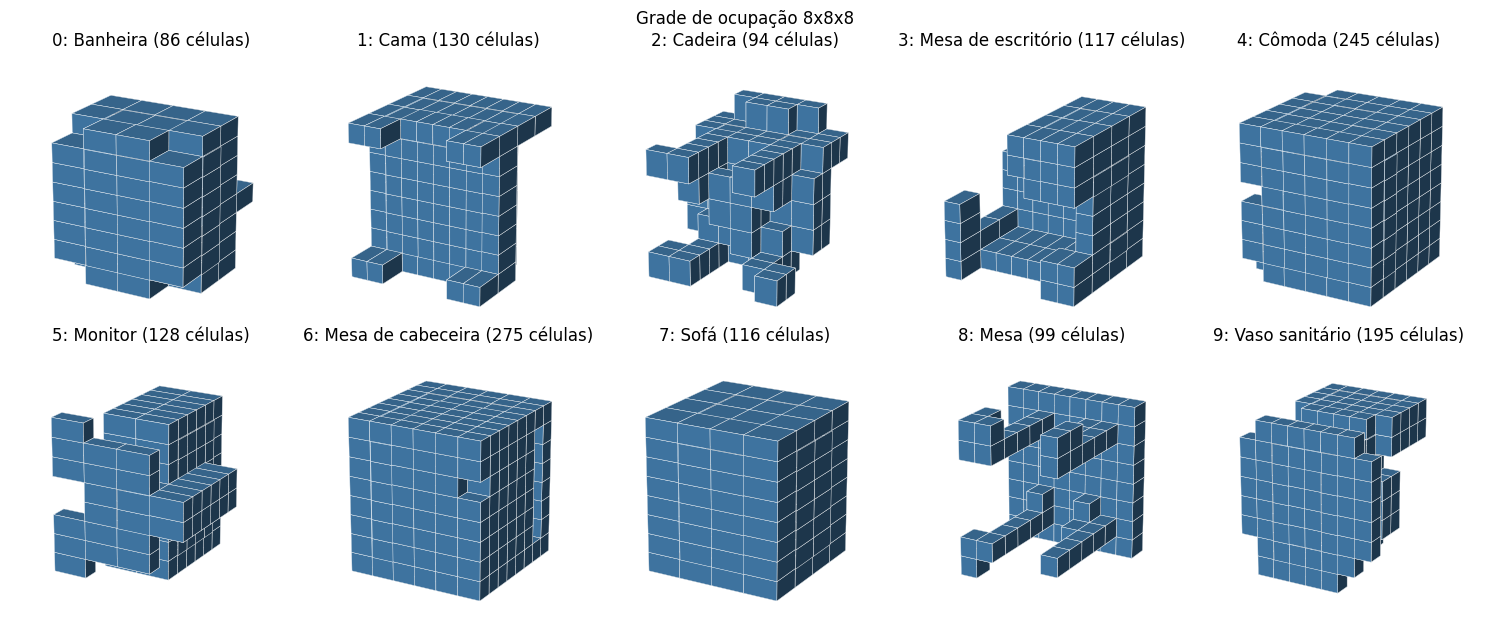

In [10]:
fig = plt.figure(figsize=(15, 6.5))
for c in range(10):
    # Primeiro objeto de treino da classe c, reorganizado como grade (x, y, z)
    i = np.where(y_train == c)[0][0]
    grid3d = X_train[i].reshape(GRID, GRID, GRID).astype(bool)

    ax = fig.add_subplot(2, 5, c + 1, projection='3d')
    ax.voxels(grid3d, facecolors='steelblue', edgecolor='white', linewidth=0.3)

    # Mesmo ângulo e escala dos gráficos da etapa 2
    ax.view_init(elev=20, azim=-60)
    ax.set_box_aspect((1, 1, 1))
    ax.set_title(f'{c}: {CLASS_NAMES[c]} ({grid3d.sum()} células)'); ax.set_axis_off()

fig.suptitle('Grade de ocupação 8x8x8')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '03_grade_ocupacao.png', dpi=150, bbox_inches='tight')
plt.show()

## Etapa 4: Avaliação e baseline

- **Validação:** validação cruzada estratificada de **3 folds**, só no conjunto de treino. Os folds são criados uma vez e reutilizados em todos os experimentos (baseline, Random Search, TPE e sensibilidade).
- **Métrica principal:** **F1 macro** (média do F1 de cada classe, sem ponderar pelo tamanho), adequada ao desbalanceamento. Registramos também accuracy e tempo.
- **Modelo:** `Pipeline` com `StandardScaler` e `MLPClassifier`. A padronização é ajustada dentro de cada fold, só com os dados de treino do fold.
- **Baseline:** MLP com os valores padrão do scikit-learn, sem busca de hiperparâmetros.

O conjunto de teste continua intocado.

### 4.1 Folds

In [11]:
from sklearn.model_selection import StratifiedKFold

# Número de folds e splitter; shuffle com seed fixa deixa os folds reprodutíveis
N_FOLDS = 3
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

# Lista de (índices de treino, índices de validação), reutilizada em todas as etapas
FOLDS = list(skf.split(X_train, y_train))

# Tamanho de cada fold e proporção de cada classe na validação (deve ser parecida entre folds)
for k, (tr, va) in enumerate(FOLDS, start=1):
    print(f'fold {k}: treino={len(tr)} | validação={len(va)}')

prop = pd.DataFrame({f'fold {k}': np.bincount(y_train[va], minlength=10) / len(va)
                     for k, (_, va) in enumerate(FOLDS, start=1)})
prop.index = [f'{i}: {n}' for i, n in enumerate(CLASS_NAMES)]
display((100 * prop).round(1))

fold 1: treino=2660 | validação=1331
fold 2: treino=2661 | validação=1330
fold 3: treino=2661 | validação=1330


,fold 1,fold 2,fold 3
0: Banheira,2.7,2.6,2.6
1: Cama,12.9,12.9,12.9
2: Cadeira,22.3,22.3,22.3
3: Mesa de escritório,5.0,5.0,5.0
4: Cômoda,5.0,5.0,5.0
5: Monitor,11.6,11.7,11.7
6: Mesa de cabeceira,5.0,5.0,5.0
7: Sofá,17.1,17.1,17.0
8: Mesa,9.8,9.8,9.8
9: Vaso sanitário,8.6,8.6,8.6


### 4.2 Pipeline e função de avaliação

`FIXED_PARAMS` reúne o que **não** será buscado (Adam e critérios de parada) e é reaproveitado nas buscas da etapa 5. Parada antecipada limita o tempo de cada treino, o que importa para 50 trials.

In [12]:
import time
import warnings
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Parâmetros fixos em todos os experimentos (não fazem parte da busca)
FIXED_PARAMS = dict(solver='adam', max_iter=200, early_stopping=True,
                    n_iter_no_change=10, random_state=SEED)


def make_pipeline(**mlp_params):
    """Monta o Pipeline (padronização + MLP) com os parâmetros fixos e os informados."""
    return Pipeline([
        ('scaler', StandardScaler()),
        ('mlp', MLPClassifier(**FIXED_PARAMS, **mlp_params)),
    ])


def cross_evaluate(pipeline, X, y, folds=FOLDS):
    """Avalia o pipeline nos folds e devolve uma linha por fold com métricas e tempo."""
    rows = []
    for k, (tr, va) in enumerate(folds, start=1):
        # Cópia limpa do pipeline para cada fold, sem estado do fold anterior
        model = clone(pipeline)

        start = time.perf_counter()
        with warnings.catch_warnings():
            # Sem convergência completa em max_iter é esperado com parada antecipada
            warnings.simplefilter('ignore', ConvergenceWarning)
            model.fit(X[tr], y[tr])
        elapsed = time.perf_counter() - start

        pred_va, pred_tr = model.predict(X[va]), model.predict(X[tr])
        rows.append({
            'fold': k,
            'f1_macro': f1_score(y[va], pred_va, average='macro'),
            'accuracy': accuracy_score(y[va], pred_va),
            # F1 no próprio treino do fold: ajuda a diagnosticar overfitting
            'f1_macro_treino': f1_score(y[tr], pred_tr, average='macro'),
            'tempo_s': elapsed,
        })
    return pd.DataFrame(rows).set_index('fold')

### 4.3 Baseline

MLP com os valores padrão do scikit-learn: uma camada oculta de 100 neurônios, ReLU, `alpha=1e-4`, taxa de aprendizado `1e-3` e lote automático (`min(200, n)`).

In [13]:
# Baseline: nenhum hiperparâmetro informado, então valem os padrões do scikit-learn
baseline = make_pipeline()
baseline_folds = cross_evaluate(baseline, X_train, y_train)
display(baseline_folds.round(4))

# Resumo: média e desvio padrão entre os folds
baseline_summary = baseline_folds.agg(['mean', 'std']).round(4)
display(baseline_summary)

# Guarda para comparar com Random Search e TPE na etapa 5
baseline_summary.to_csv(OUTPUT_DIR / 'baseline_cv.csv')

,f1_macro,accuracy,f1_macro_treino,tempo_s
fold,,,,
1,0.8673,0.9166,0.9718,4.1225
2,0.8791,0.9218,0.9750,3.9473
3,0.8638,0.9090,0.9417,2.6129


,f1_macro,accuracy,f1_macro_treino,tempo_s
mean,0.8701,0.9158,0.9628,3.5609
std,0.0080,0.0064,0.0184,0.8257


## Etapa 5: Random Search e TPE

Duas estratégias de busca com o **mesmo** espaço, os **mesmos folds**, a mesma métrica (F1 macro médio nos 3 folds) e a mesma seed:

- **Random Search:** 25 configurações sorteadas ao acaso.
- **TPE (Optuna):** 25 trials; a cada trial o TPE usa os resultados anteriores para escolher a próxima configuração.

O conjunto de teste não participa de nenhuma das buscas.

### 5.1 Espaço de busca e função objetivo

| Hiperparâmetro | Valores |
| --- | --- |
| Camadas ocultas | `(64,)`, `(128,)` ou `(64, 64)` |
| Ativação | ReLU ou tanh |
| `alpha` | 1e-5 a 1e-2 (escala logarítmica) |
| Taxa de aprendizado | 1e-4 a 1e-2 (escala logarítmica) |
| Tamanho do lote | 32, 64 ou 128 |

Adam e os critérios de parada ficam fixos (`FIXED_PARAMS`).

In [14]:
# Quantidade de configurações em cada busca
N_TRIALS = 25

# Espaço de busca, definido uma única vez e usado pelas duas estratégias
HIDDEN_OPTIONS = {'(64,)': (64,), '(128,)': (128,), '(64, 64)': (64, 64)}
ACTIVATIONS = ['relu', 'tanh']
ALPHA_RANGE = (1e-5, 1e-2)
LR_RANGE = (1e-4, 1e-2)
BATCH_SIZES = [32, 64, 128]


def to_mlp_params(cfg):
    """Converte uma configuração da busca nos parâmetros do MLPClassifier."""
    return dict(hidden_layer_sizes=HIDDEN_OPTIONS[cfg['hidden']],
                activation=cfg['activation'],
                alpha=cfg['alpha'],
                learning_rate_init=cfg['learning_rate_init'],
                batch_size=cfg['batch_size'])


def evaluate_config(cfg):
    """Avalia uma configuração nos folds e devolve as métricas médias e o tempo total."""
    res = cross_evaluate(make_pipeline(**to_mlp_params(cfg)), X_train, y_train)
    return {'f1_macro': res['f1_macro'].mean(),
            'accuracy': res['accuracy'].mean(),
            'f1_macro_treino': res['f1_macro_treino'].mean(),
            'tempo_s': res['tempo_s'].sum()}

### 5.2 Random Search (25 configurações)

In [15]:
def sample_config(rng):
    """Sorteia uma configuração do espaço; alpha e taxa de aprendizado em escala logarítmica."""
    return {
        'hidden': str(rng.choice(list(HIDDEN_OPTIONS))),
        'activation': str(rng.choice(ACTIVATIONS)),
        'alpha': float(10 ** rng.uniform(np.log10(ALPHA_RANGE[0]), np.log10(ALPHA_RANGE[1]))),
        'learning_rate_init': float(10 ** rng.uniform(np.log10(LR_RANGE[0]), np.log10(LR_RANGE[1]))),
        'batch_size': int(rng.choice(BATCH_SIZES)),
    }


# Gerador com seed fixa: as 25 configurações são sempre as mesmas
rng = np.random.default_rng(SEED)

rs_rows = []
start = time.perf_counter()
for t in range(1, N_TRIALS + 1):
    cfg = sample_config(rng)
    rs_rows.append({'trial': t, **cfg, **evaluate_config(cfg)})
rs_search_time = time.perf_counter() - start

rs_df = pd.DataFrame(rs_rows)
rs_df.to_csv(OUTPUT_DIR / 'random_search_trials.csv', index=False)
print(f'Random Search: {rs_search_time:.0f} s no total')
display(rs_df.sort_values('f1_macro', ascending=False).head(5).round(4))

Random Search: 373 s no total


,trial,hidden,activation,alpha,learning_rate_init,batch_size,f1_macro,accuracy,f1_macro_treino,tempo_s
4,5,"(128,)",relu,0.0000,0.0013,128,0.8875,0.9228,0.9671,12.7173
12,13,"(128,)",tanh,0.0001,0.0046,64,0.8848,0.9223,0.9666,9.3484
3,4,"(128,)",relu,0.0009,0.0044,128,0.8842,0.9213,0.9691,10.8853
20,21,"(64, 64)",relu,0.0002,0.0051,32,0.8827,0.9218,0.9637,8.1697
24,25,"(128,)",relu,0.0000,0.0028,128,0.8817,0.9208,0.9694,4.1534


### 5.3 TPE com Optuna (25 trials)

In [16]:
import optuna

# Só mostra avisos; o progresso de cada trial já fica na tabela
optuna.logging.set_verbosity(optuna.logging.WARNING)


def objective(trial):
    """Sugere uma configuração do mesmo espaço do Random Search e devolve o F1 macro médio."""
    cfg = {
        'hidden': trial.suggest_categorical('hidden', list(HIDDEN_OPTIONS)),
        'activation': trial.suggest_categorical('activation', ACTIVATIONS),
        'alpha': trial.suggest_float('alpha', *ALPHA_RANGE, log=True),
        'learning_rate_init': trial.suggest_float('learning_rate_init', *LR_RANGE, log=True),
        'batch_size': trial.suggest_categorical('batch_size', BATCH_SIZES),
    }
    res = evaluate_config(cfg)

    # Guarda as outras métricas no trial para montar a tabela depois
    for key in ('accuracy', 'f1_macro_treino', 'tempo_s'):
        trial.set_user_attr(key, res[key])
    return res['f1_macro']


# Seed fixa no sampler TPE; maximizamos o F1 macro
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))

start = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS)
tpe_search_time = time.perf_counter() - start

tpe_df = pd.DataFrame([{
    'trial': t.number + 1, **t.params, 'f1_macro': t.value, **t.user_attrs,
} for t in study.trials])
tpe_df.to_csv(OUTPUT_DIR / 'tpe_trials.csv', index=False)
print(f'TPE: {tpe_search_time:.0f} s no total')
display(tpe_df.sort_values('f1_macro', ascending=False).head(5).round(4))

TPE: 230 s no total


,trial,hidden,activation,alpha,learning_rate_init,batch_size,f1_macro,accuracy,f1_macro_treino,tempo_s
7,8,"(64,)",relu,0.0015,0.0035,64,0.8817,0.9223,0.9740,5.1049
21,22,"(128,)",relu,0.0007,0.0004,64,0.8816,0.9213,0.9710,13.2877
1,2,"(128,)",relu,0.0000,0.0004,32,0.8814,0.9208,0.9662,12.2727
4,5,"(128,)",relu,0.0010,0.0004,64,0.8801,0.9201,0.9690,11.3587
19,20,"(128,)",relu,0.0000,0.0025,32,0.8783,0.9178,0.9660,13.2372


### 5.4 Melhores parâmetros e comparação

Baseline, Random Search e TPE lado a lado (métricas de validação cruzada; o teste continua reservado).

In [17]:
def best_row(df):
    """Linha do trial com maior F1 macro."""
    return df.loc[df['f1_macro'].idxmax()]


rs_best, tpe_best = best_row(rs_df), best_row(tpe_df)
print('Melhor Random Search:', rs_best[['hidden', 'activation', 'alpha', 'learning_rate_init', 'batch_size']].to_dict())
print('Melhor TPE          :', tpe_best[['hidden', 'activation', 'alpha', 'learning_rate_init', 'batch_size']].to_dict())

# Tabela comparativa; o baseline usa a média dos folds calculada na etapa 4
comparison = pd.DataFrame({
    'baseline': {'f1_macro': baseline_folds['f1_macro'].mean(),
                 'accuracy': baseline_folds['accuracy'].mean(),
                 'f1_macro_treino': baseline_folds['f1_macro_treino'].mean(),
                 'tempo_busca_s': np.nan},
    'random_search': {'f1_macro': rs_best['f1_macro'], 'accuracy': rs_best['accuracy'],
                      'f1_macro_treino': rs_best['f1_macro_treino'], 'tempo_busca_s': rs_search_time},
    'tpe': {'f1_macro': tpe_best['f1_macro'], 'accuracy': tpe_best['accuracy'],
            'f1_macro_treino': tpe_best['f1_macro_treino'], 'tempo_busca_s': tpe_search_time},
}).T
display(comparison.round(4))
comparison.to_csv(OUTPUT_DIR / 'comparacao_baseline_buscas.csv')

# Melhor configuração entre as duas buscas, usada na sensibilidade e no modelo final
best_source = 'tpe' if tpe_best['f1_macro'] >= rs_best['f1_macro'] else 'random_search'
winner = tpe_best if best_source == 'tpe' else rs_best

# Converte para tipos nativos do Python, sem os tipos do numpy
BEST_CFG = {'hidden': str(winner['hidden']), 'activation': str(winner['activation']),
            'alpha': float(winner['alpha']),
            'learning_rate_init': float(winner['learning_rate_init']),
            'batch_size': int(winner['batch_size'])}
print('Melhor configuração geral (%s):' % best_source, BEST_CFG)

Melhor Random Search: {'hidden': '(128,)', 'activation': 'relu', 'alpha': 4.8052519691574605e-05, 'learning_rate_init': 0.0012857886092104667, 'batch_size': 128}
Melhor TPE          : {'hidden': '(64,)', 'activation': 'relu', 'alpha': 0.0015382308040279, 'learning_rate_init': 0.0034877126245459306, 'batch_size': 64}


,f1_macro,accuracy,f1_macro_treino,tempo_busca_s
baseline,0.8701,0.9158,0.9628,NaN
random_search,0.8875,0.9228,0.9671,372.5813
tpe,0.8817,0.9223,0.9740,230.4055


Melhor configuração geral (random_search): {'hidden': '(128,)', 'activation': 'relu', 'alpha': 4.8052519691574605e-05, 'learning_rate_init': 0.0012857886092104667, 'batch_size': 128}


### 5.5 Evolução das buscas

Cada ponto é um trial; a linha é o melhor F1 macro encontrado até aquele trial. A linha tracejada é o baseline.

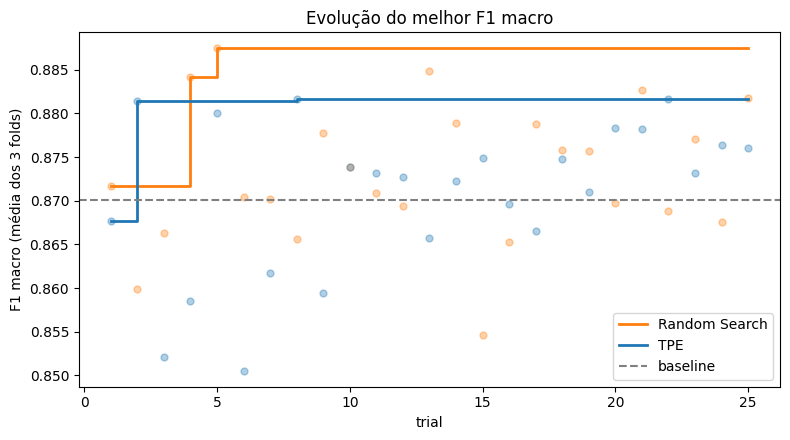

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))

for df, nome, cor in [(rs_df, 'Random Search', 'tab:orange'), (tpe_df, 'TPE', 'tab:blue')]:
    # Pontos: resultado de cada trial; linha: melhor valor acumulado
    ax.scatter(df['trial'], df['f1_macro'], color=cor, alpha=0.35, s=25)
    ax.step(df['trial'], df['f1_macro'].cummax(), where='post', color=cor, label=nome, linewidth=2)

# Referência: baseline sem busca
ax.axhline(baseline_folds['f1_macro'].mean(), color='gray', linestyle='--', label='baseline')
ax.set_xlabel('trial'); ax.set_ylabel('F1 macro (média dos 3 folds)')
ax.set_title('Evolução do melhor F1 macro')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '04_evolucao_buscas.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.6 Importância dos hiperparâmetros (TPE)

Estimada pelo Optuna a partir dos 25 trials do TPE. Com um orçamento tão curto, a importância é **apenas indicativa**.

,importância
learning_rate_init,0.341
batch_size,0.335
hidden,0.263
alpha,0.055
activation,0.006


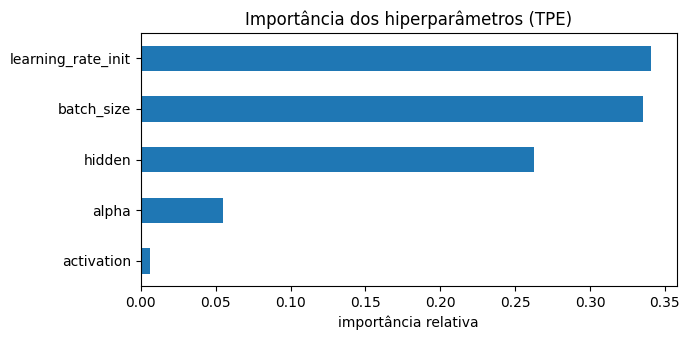

In [19]:
# Importância relativa de cada hiperparâmetro no F1 macro (soma 1)
importance = optuna.importance.get_param_importances(study)
imp = pd.Series(importance).sort_values()
display(imp.sort_values(ascending=False).round(3).to_frame('importância'))

fig, ax = plt.subplots(figsize=(7, 3.5))
imp.plot.barh(ax=ax, color='tab:blue')
ax.set_xlabel('importância relativa'); ax.set_title('Importância dos hiperparâmetros (TPE)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '05_importancia_hiperparametros.png', dpi=150, bbox_inches='tight')
plt.show()

## Etapa 6: Análise de sensibilidade

Varia **um** hiperparâmetro por vez, mantendo os demais na melhor configuração encontrada (`BEST_CFG`). Cada valor é avaliado nos mesmos folds (`FOLDS`), com F1 macro e accuracy; o teste continua reservado.

### 6.1 Sensibilidade do `alpha`

`alpha` é a regularização L2: valores maiores penalizam pesos grandes e tendem a reduzir o overfitting. Testamos 7 valores em escala logarítmica, cobrindo todo o intervalo da busca.

In [20]:
# 7 valores de alpha em escala logarítmica, cobrindo o intervalo da busca
ALPHA_VALUES = np.logspace(np.log10(ALPHA_RANGE[0]), np.log10(ALPHA_RANGE[1]), 7)

sens_rows = []
for a in ALPHA_VALUES:
    # Só o alpha muda; o restante fica na melhor configuração
    sens_rows.append({'alpha': float(a), **evaluate_config({**BEST_CFG, 'alpha': float(a)})})

sens_df = pd.DataFrame(sens_rows)
sens_df.to_csv(OUTPUT_DIR / 'sensibilidade_alpha.csv', index=False)
display(sens_df.round(4))


,alpha,f1_macro,accuracy,f1_macro_treino,tempo_s
0,0.0000,0.8878,0.9231,0.9671,5.6159
1,0.0000,0.8875,0.9228,0.9671,5.4295
2,0.0001,0.8860,0.9221,0.9673,5.4770
3,0.0003,0.8828,0.9208,0.9708,5.6632
4,0.0010,0.8839,0.9211,0.9701,5.7783
5,0.0032,0.8863,0.9223,0.9670,5.5242
6,0.0100,0.8860,0.9221,0.9683,5.8162


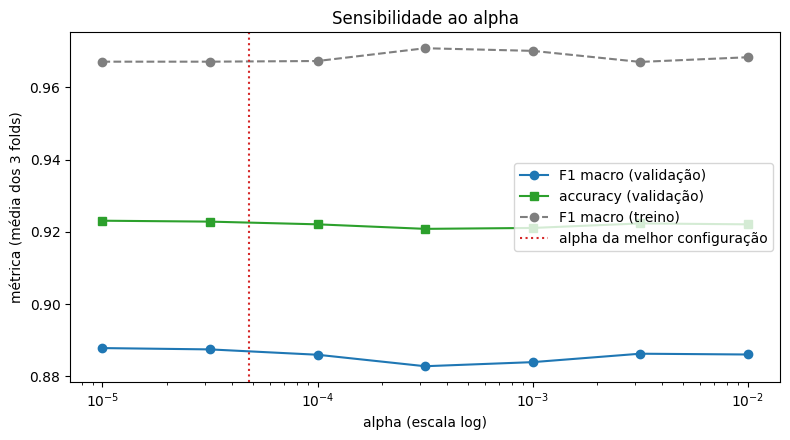

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sens_df['alpha'], sens_df['f1_macro'], 'o-', color='tab:blue', label='F1 macro (validação)')
ax.plot(sens_df['alpha'], sens_df['accuracy'], 's-', color='tab:green', label='accuracy (validação)')

# F1 no treino do fold, tracejado, para enxergar o overfitting
ax.plot(sens_df['alpha'], sens_df['f1_macro_treino'], 'o--', color='tab:gray', label='F1 macro (treino)')

# Marca o alpha da melhor configuração das buscas
ax.axvline(BEST_CFG['alpha'], color='tab:red', linestyle=':', label='alpha da melhor configuração')
ax.set_xscale('log')
ax.set_xlabel('alpha (escala log)'); ax.set_ylabel('métrica (média dos 3 folds)')
ax.set_title('Sensibilidade ao alpha')
ax.legend(loc='center right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '06_sensibilidade_alpha.png', dpi=150, bbox_inches='tight')
plt.show()


### 6.2 Interpretação

- O F1 macro de validação varia só de **0,883 a 0,888** ao longo de três ordens de grandeza de `alpha`. Essa variação (cerca de 0,005) é menor que o desvio entre folds do baseline (0,008), então o `alpha` tem efeito pequeno e não distinguível do ruído neste orçamento.
- Os melhores valores ficam nos `alpha` menores (1e-5 a 1e-4) e há um leve vale perto de 3e-4, sem tendência clara. Isso é coerente com a importância baixa do `alpha` no TPE (seção 5.6).
- O F1 macro no treino fica quase constante (0,967 a 0,971): aumentar a regularização até 1e-2 não reduziu a distância entre treino e validação (cerca de 0,08), então o `alpha` sozinho não resolve o overfitting.
- Limitação: um único hiperparâmetro, os demais fixos na melhor configuração, e a mesma seed em todos os valores.


## Etapa 7: Modelo final e avaliação no teste

A melhor configuração das buscas (`BEST_CFG`) é treinada com **todo** o conjunto de treino e avaliada **uma única vez** no teste reservado. O teste não foi usado em nenhuma decisão anterior: nem nas buscas, nem na validação cruzada, nem na sensibilidade.

### 7.1 Treino final e predição no teste

In [22]:
from sklearn.metrics import classification_report, confusion_matrix

# Modelo final: melhor configuração, treinada com todo o treino (sem folds)
final_model = make_pipeline(**to_mlp_params(BEST_CFG))
with warnings.catch_warnings():
    # Sem convergência completa em max_iter é esperado com parada antecipada
    warnings.simplefilter('ignore', ConvergenceWarning)
    final_model.fit(X_train, y_train)

# Única vez em que o teste é usado: uma predição, sem ajustar nada depois
y_pred = final_model.predict(X_test)

test_f1 = f1_score(y_test, y_pred, average='macro')
test_acc = accuracy_score(y_test, y_pred)
print(f'F1 macro no teste : {test_f1:.4f}')
print(f'Accuracy no teste : {test_acc:.4f}')

# Referência: F1 macro de validação cruzada da mesma configuração
cv_f1 = max(rs_best['f1_macro'], tpe_best['f1_macro'])
print(f'F1 macro na validação cruzada: {cv_f1:.4f}')

pd.DataFrame({'f1_macro': [test_f1], 'accuracy': [test_acc], 'f1_macro_validacao_cruzada': [cv_f1]}
             ).to_csv(OUTPUT_DIR / 'resultado_final_teste.csv', index=False)


F1 macro no teste : 0.8534
Accuracy no teste : 0.8568
F1 macro na validação cruzada: 0.8875


### 7.2 Relatório por classe

In [23]:
# Precisão, recall e F1 de cada classe
report = pd.DataFrame(classification_report(
    y_test, y_pred, target_names=CLASS_NAMES, output_dict=True)).T
display(report.round(3))
report.to_csv(OUTPUT_DIR / 'relatorio_por_classe_teste.csv')


,precision,recall,f1-score,support
Banheira,1.000,0.840,0.913,50.000
Cama,0.884,0.990,0.934,100.000
Cadeira,0.970,0.970,0.970,100.000
Mesa de escritório,0.638,0.698,0.667,86.000
Cômoda,0.756,0.756,0.756,86.000
Monitor,0.990,0.960,0.975,100.000
Mesa de cabeceira,0.693,0.709,0.701,86.000
Sofá,0.923,0.960,0.941,100.000
Mesa,0.761,0.670,0.713,100.000
Vaso sanitário,0.979,0.950,0.964,100.000


### 7.3 Matriz de confusão

Linhas são a classe real e colunas a prevista; cada linha é normalizada (recall por classe).

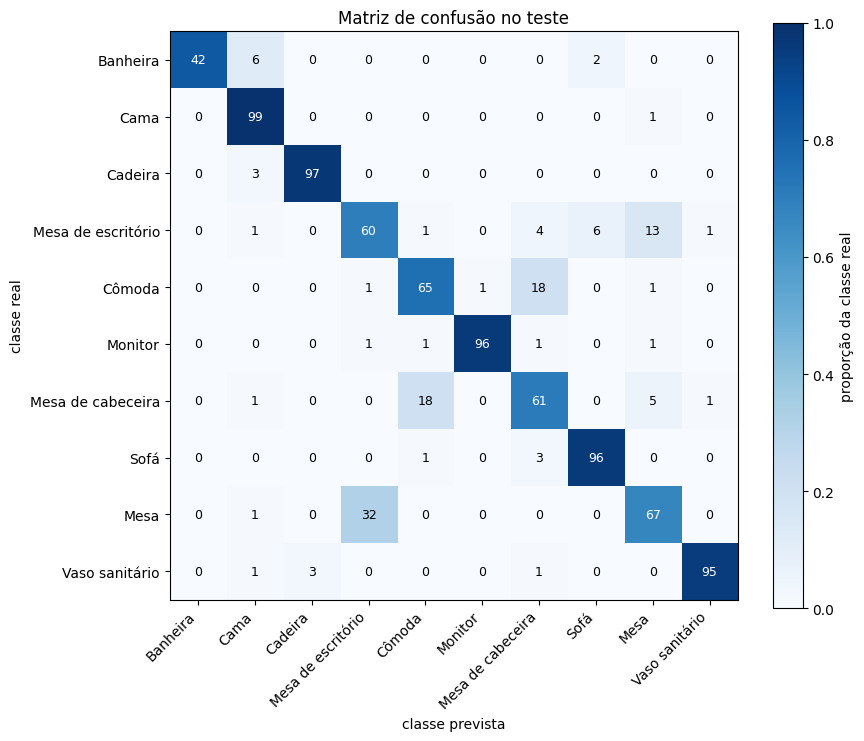

In [24]:
cm = confusion_matrix(y_test, y_pred)

# Normaliza por linha para comparar classes de tamanhos diferentes
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES)

# Contagem absoluta em cada célula, em branco quando o fundo é escuro
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm_norm[i, j] > 0.5 else 'black', fontsize=9)
ax.set_xlabel('classe prevista'); ax.set_ylabel('classe real')
ax.set_title('Matriz de confusão no teste')
fig.colorbar(im, ax=ax, label='proporção da classe real')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '07_matriz_confusao.png', dpi=150, bbox_inches='tight')
plt.show()


### 7.4 Interpretação

- No teste, o modelo final obteve **F1 macro 0,853** e **accuracy 0,857**, abaixo da validação cruzada (F1 macro 0,887; accuracy 0,923). A queda de cerca de 0,03 no F1 macro é maior que o desvio entre folds do baseline (0,008).
- As classes **Cadeira, Monitor, Vaso sanitário, Sofá e Cama** têm F1 acima de 0,93. As piores são **Mesa de escritório (0,667)**, **Mesa de cabeceira (0,701)**, **Mesa (0,713)** e **Cômoda (0,756)**.
- A matriz de confusão mostra que os erros se concentram em móveis de formato parecido: 32 mesas previstas como mesa de escritório, 18 cômodas previstas como mesa de cabeceira e 18 no sentido inverso. A grade 8×8×8 é grossa e provavelmente não separa esses formatos.
- A accuracy cai mais que o F1 macro porque o teste é mais equilibrado que o treino: as classes difíceis têm cerca de 86 a 100 objetos no teste, um peso maior que o que têm na validação cruzada.
- Isso é uma hipótese, não foi testada. A queda também pode vir de seleção da melhor entre 50 configurações na validação, que tende a ser otimista.


## Etapa 8: Interpretação e conclusões

Síntese dos resultados das etapas anteriores. Os números vêm das tabelas em `output/`.

### 8.1 Baseline versus modelos ajustados

| Modelo | F1 macro (validação cruzada) |
| --- | --- |
| Baseline (MLP padrão) | 0,870 |
| Random Search (25) | 0,887 |
| TPE (25) | 0,882 |

O ajuste melhora o F1 macro em 0,01 a 0,02. O ganho é pequeno e da ordem do desvio entre folds do baseline (0,008), então é um ganho real mas modesto.

### 8.2 Random Search versus TPE

A diferença entre os métodos (0,006) é menor que o desvio entre folds, então com 25 trials não dá para afirmar que um é melhor. O TPE chegou a 0,881 já no trial 2, mas não passou de 0,882. Os tempos de busca variaram muito entre execuções (Random Search de 333 a 579 s, TPE de 230 a 656 s), por isso não permitem concluir qual é mais rápido.

### 8.3 Sensibilidade e importância dos hiperparâmetros

- O `alpha` quase não influencia: o F1 macro varia de 0,883 a 0,888 em três ordens de grandeza, dentro do ruído.
- A importância estimada pelo TPE aponta taxa de aprendizado (0,34), tamanho do lote (0,33) e camadas ocultas (0,26) como os mais relevantes, e `alpha` (0,06) e ativação (0,01) como pouco relevantes. Com 25 trials, isso é apenas indicativo.

### 8.4 Overfitting e underfitting

- No treino de cada fold, o F1 macro fica em 0,96 a 0,97, contra 0,87 a 0,89 na validação: uma diferença de cerca de 0,08 a 0,09. Há **sinais de overfitting**.
- O ajuste e o aumento do `alpha` não reduziram essa diferença, e o TPE escolheu um modelo com F1 de treino maior (0,974) e validação parecida.
- Não há sinal de underfitting: o treino chega perto de 0,97.
- No teste, o F1 macro foi 0,853, abaixo da validação cruzada (0,887), o que reforça o overfitting e o otimismo de escolher a melhor entre 50 configurações.

### 8.5 Limitações

- A grade 8×8×8 é grossa e descarta o tamanho absoluto do objeto; as confusões entre mesa, mesa de escritório, cômoda e mesa de cabeceira mostram esse limite.
- Orçamento curto: 25 trials por busca, 3 folds e uma única seed (42), sem repetir os experimentos.
- A sensibilidade cobre só o `alpha`, com os demais hiperparâmetros fixos.
- O treino é desbalanceado e o teste é mais equilibrado, o que ajuda a explicar a diferença entre validação e teste (hipótese não testada).

### 8.6 Decisões da análise

- Entrada: grade de ocupação binária 8×8×8 (512 atributos), determinística e igual para treino e teste.
- Avaliação: validação cruzada estratificada de 3 folds e F1 macro, com os mesmos folds em todos os experimentos.
- Buscas: mesmo espaço, mesmos folds, mesma métrica e 25 configurações cada; a melhor configuração geral foi a do Random Search.
- Teste: usado uma única vez, na Etapa 7.